In [ ]:
import numpy as np
import pandas as pd
file_path= r"File path of data saved on your computer.csv"

data= pd.read_csv(file_path)

print(data.head())
print(data.columns)
print(data.shape)


             CID  IDSURVEY      zHD   zHDERR     zCMB  zCMBERR     zHEL  \
0         2011fe        51  0.00122  0.00084  0.00122  0.00002  0.00082   
1         2011fe        56  0.00122  0.00084  0.00122  0.00002  0.00082   
2         2012cg        51  0.00256  0.00084  0.00256  0.00002  0.00144   
3         2012cg        56  0.00256  0.00084  0.00256  0.00002  0.00144   
4  1994DRichmond        50  0.00299  0.00084  0.00299  0.00004  0.00187   

   zHELERR  m_b_corr  m_b_corr_err_DIAG  ...  PKMJDERR  NDOF   FITCHI2  \
0  0.00002   9.74571           1.516210  ...    0.1071    36   26.8859   
1  0.00002   9.80286           1.517230  ...    0.0579   101   88.3064   
2  0.00002  11.47030           0.781906  ...    0.0278   165  233.5000   
3  0.00002  11.49190           0.798612  ...    0.0667    55  100.1220   
4  0.00004  11.52270           0.880798  ...    0.0522   146  109.8390   

    FITPROB  m_b_corr_err_RAW  m_b_corr_err_VPEC  biasCor_m_b  biasCorErr_m_b  \
0  0.864470            

In [ ]:
z=data["zHD"]
mu_obs=data["MU_SH0ES"]
mu_err=data["MU_SH0ES_ERR_DIAG"]

In [ ]:
def E_LCDM(z,omega_m):
    return np.sqrt(omega_m*(1+z)**3 + (1-omega_m))


In [ ]:
from scipy.integrate import quad
def luminosity_distance(z, omega_m, H0=70):
    integral, error = quad(
        lambda zp:1/E_LCDM(zp, omega_m),
        0,
        z
    )
    c=299792.458
    D_C = (c/H0)*integral
    D_L = (1+z)*D_C
    return D_L


In [ ]:
def distance_modulus(z,omega_m, H0=70):
    D_L=luminosity_distance(z,omega_m, H0)
    mu=5*np.log10(D_L)+25
    return mu

In [ ]:
def log_likelihood(omega_m):
    DL_values=[]

    for z_i in z:
        DL_i=luminosity_distance(z_i,omega_m)
        DL_values.append(DL_i)
    mu_model=[]
    for DL_i in DL_values:
        mu_i=5*np.log10(DL_i)+25
        mu_model.append(mu_i)

    residuals=mu_obs-np.array(mu_model)
    chi2 = np.sum((residuals/mu_err)**2)
    return -0.5*chi2


In [ ]:
def log_prior(omega_m):
    if 0< omega_m <1:
        return 0.0
    else:
        return -np.inf

In [ ]:
def log_probability(theta):
    omega_m=theta[0]

    lp=log_prior(omega_m)

    if not np.isfinite(lp):
        return -np.inf
    return lp+log_likelihood(omega_m)

In [ ]:
import emcee
ndim=1 #number of parameters being sampled as this is LCDM only need omega_m
nwalkers=10
initial_positions= 0.5+0.01*np.random.randn(nwalkers, ndim) #to tell where the walker starts
sampler=emcee.EnsembleSampler(
    nwalkers,
    ndim,
    log_probability
) #basically n walkers exploring ndim parameters and this is the function defining my posterior

nsteps=100
sampler.run_mcmc(initial_positions, nsteps, progress=True) #start the nwalkers at initial_positions and let them evolve for nsteps

You must install the tqdm library to use progress indicators with emcee


State([[0.54952543]
 [0.53115193]
 [0.53780294]
 [0.51761604]
 [0.52178767]
 [0.52825327]
 [0.53809404]
 [0.49259099]
 [0.53697724]
 [0.5242533 ]], log_prob=[-437.1232493  -436.62594677 -436.61838415 -437.31424942 -437.00478267
 -436.69687931 -436.62295542 -441.04444467 -436.60764499 -436.86285857], blobs=None, random_state=('MT19937', array([2139967562, 4263726087, 1945863787, 3523894480, 1281838907,
       3091860733,   21563916, 1480551384, 2782167923, 2262669322,
       2123441964, 4135893399, 1112782433, 1513302863, 1351545700,
        854323920, 2778115628, 1538756076, 3433101472, 1396898933,
       3084365789, 4078051969, 2145446469, 3487877417, 3771455876,
       1519606231, 1525363539, 2363278585, 3090279016, 3363961264,
       4032312879, 3295091841, 1677028925, 4235479842, 2793854267,
       3093405279, 2036383950,  291530783, 2047690751, 2421763001,
       1761800107, 4268639012,  389432111,  255522190, 3732839260,
       1755678559, 2578860091, 1243366995, 2304539046,   34

In [ ]:
chain=sampler.get_chain()
print(chain.shape)

(100, 10, 1)


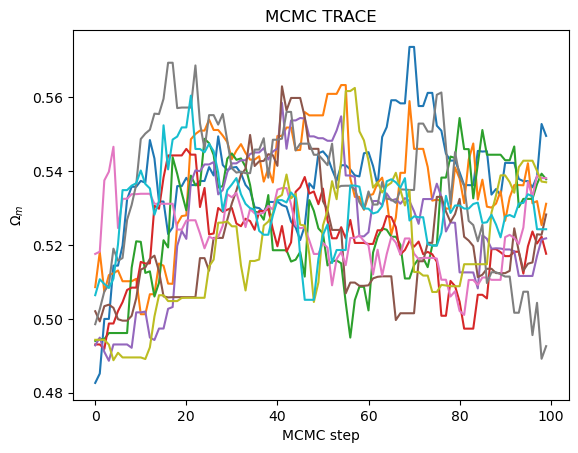

In [ ]:
import matplotlib.pyplot as plt
fig, ax=plt.subplots()
for walker in range(10):
    ax.plot(chain[:,walker,0])
ax.set_xlabel("MCMC step")
ax.set_ylabel(r"$\Omega_m$")
ax.set_title("MCMC TRACE")
plt.show()

In [ ]:
sampler.run_mcmc(None,900,progress=True)

You must install the tqdm library to use progress indicators with emcee


In [ ]:
#get the chain
chain=sampler.get_chain()
print(chain.shape)

(100, 10, 1)


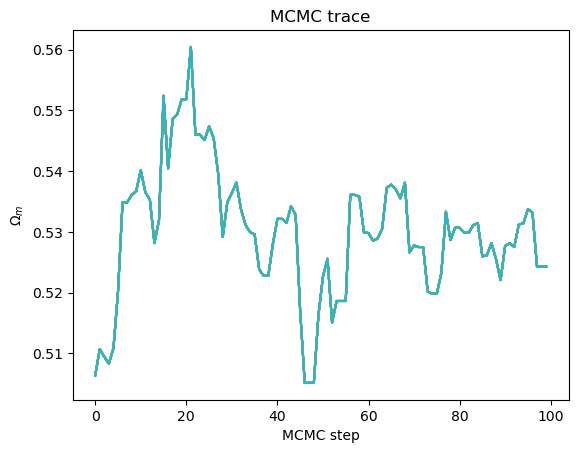

In [ ]:
fig, ax=plt.subplots()
for walkers in range(10):
    ax.plot(chain[:,walker,0])

ax.set_xlabel("MCMC step")
ax.set_ylabel(r"$\Omega_m$")
ax.set_title("MCMC trace")
plt.show()


In [ ]:
#acceptance franction ( )
#print(sampler.acceptance_fraction)
#print(np.mean(sampler.acceptance_fraction))
#A high acceptance fraction does not automatically mean a good chain.
# if almost everything is accepted, it can mean our proposal steps are too small.
# The walkers may be moving only tiny distances at a time, producing highly correlated samples.

In [ ]:
sampler.run_mcmc(None, 9000, progress=True)


You must install the tqdm library to use progress indicators with emcee


State([[0.52988605]
 [0.52074938]
 [0.5263665 ]
 [0.53350204]
 [0.52865037]
 [0.52821908]
 [0.54207204]
 [0.53640417]
 [0.53252138]
 [0.53050103]], log_prob=[-436.65184426 -437.07363836 -436.76529707 -436.59867224 -436.68471864
 -436.69796271 -436.7262972  -436.60213029 -436.60677196 -436.63828078], blobs=None, random_state=('MT19937', array([3830018628, 3964660232, 1919132995, 3329474029,   89536822,
       2928055855, 1824991223,  763264367, 2149691248, 2641200033,
         46713493, 3171946634, 2651992507,  703663246, 1628675476,
       1569494654, 1633747813, 3034272336, 2761634935,  899078906,
       3208417944, 2840487019,   24303025, 4152315439, 1103077318,
       3705975359, 2950868647, 4138844149, 1504359444, 1882853504,
       1948635061,  836473243, 3727756801, 2803568876, 3977018497,
       3547882003, 2855458907,  213777511, 2741016813, 4231722538,
       1067143290, 2307904371, 2349498868, 3347763827,  375288107,
       1735991415,  828730094, 2814316680, 1727426062, 2605

In [ ]:
chain=sampler.get_chain()
print(chain.shape)

(9100, 10, 1)


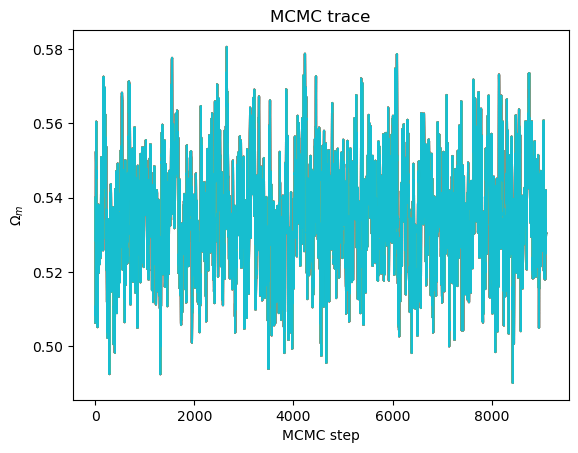

In [ ]:
fig, ax=plt.subplots()
for walkers in range(10):
    ax.plot(chain[:,walker,0])

ax.set_xlabel("MCMC step")
ax.set_ylabel(r"$\Omega_m$")
ax.set_title("MCMC trace")
plt.show()


In [ ]:
#Burn-in

#Remove the initial part that may depend on our starting positions.

#Autocorrelation

#Successive samples are not independent.

#Convergence

#The chain has reached and is adequately sampling the target posterior.


In [ ]:
#check autocorrelation time
tau=sampler.get_autocorr_time()
print(tau)
#tau tells us how many consecutive MCMC steps remain significantly correlated

[30.21505843]


In [ ]:
burn_in=200
samples=sampler.get_chain(
    discard=burn_in,                                 #we used flat to flatten from 98000,10,1 to 98000,1, for making the posterior distribution we don't need to know which walker produced what sample
    flat=True
)
print(samples.shape)

(89000, 1)


In [ ]:
omega_m_median=np.median(samples[:,0])
print("omega_m_median=",omega_m_median)
lower= np.percentile(samples[:,0],16)
upper=np.percentile(samples[:,0],84)
print("omega_m_lower=",lower)
print("omega_m_upper=",upper)
lower_uncertainty=(omega_m_median-lower)
upper_uncertainty=(upper-omega_m_median)
print("lower uncertainty=",lower_uncertainty)
print("upper uncertainty=",upper_uncertainty)

omega_m_median= 0.5349376445439872
omega_m_lower= 0.5208409676860808
omega_m_upper= 0.5491770644261889
lower uncertainty= 0.014096676857906387
upper uncertainty= 0.014239419882201676


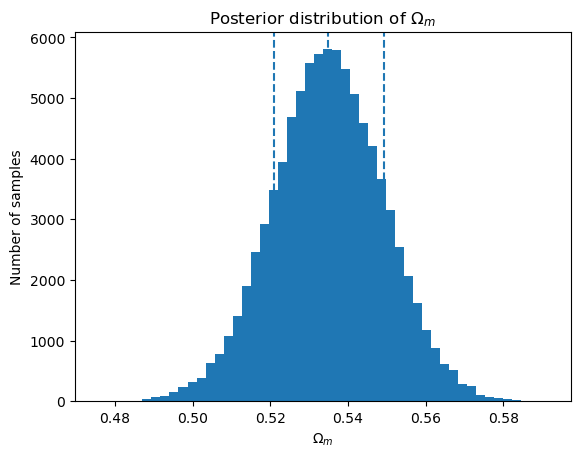

In [ ]:
#posterior distribution
fig, ax=plt.subplots()
ax.hist(samples[:,0],bins=50)

ax.axvline(lower, linestyle='--',label="16th percentile")
ax.axvline(omega_m_median,linestyle='--',label="Median")
ax.axvline(upper,linestyle="--",label="84th percentile")

ax.set_xlabel(r"$\Omega_m$")
ax.set_ylabel("Number of samples")
ax.set_title(r"Posterior distribution of $\Omega_m$")
plt.show()

In [ ]:
def E_XCDM(z,omega_m,w):
    return np.sqrt(
        omega_m*(1+z)**3+(1-omega_m)*(1+z)**(3*(1+w))
        )
print(E_LCDM(1,0.3))
print(E_XCDM(1,0.3,-1))

1.7606816861659007
1.7606816861659007
